# Homework 3

In this assigment, we will be running exploratory data analysis (EDA) on 3 datasets:
* IRIS data (`data/IRIS.csv`),
* Birdwatching data (`data/artportalen.csv`),
* Stroke Data (`data/stroke-data.csv`).

We will also be practicing data cleaning on a different dataset, `data/cell_phones_total.csv`,
which contains data for the total amount of mobile phones per country.

Don't forget to run `pip install -r environment/requirements.txt` before running code in this file.

---

### Task A: Exploratory Data Analysis

#### A1: IRIS

This subsection will be using the IRIS data.
Let's first load the data and take a peek at its structure.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns


plt.style.use("dark_background")


iris = pd.read_csv("data/IRIS.csv")
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


1\. Let's create box plots of sepal and petal features across different species
in order to distinguish any interesting features.

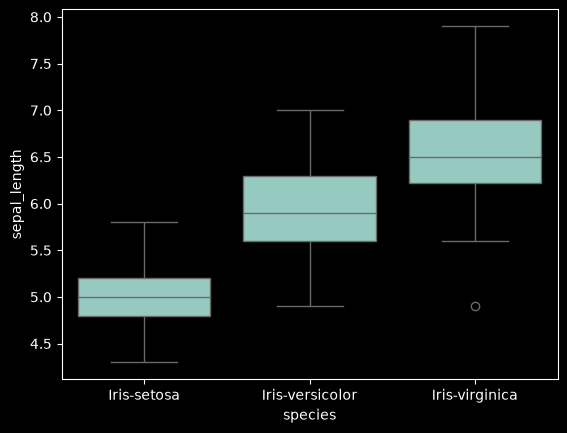

In [2]:
sns.boxplot(iris, x="species", y="sepal_length")
plt.show()

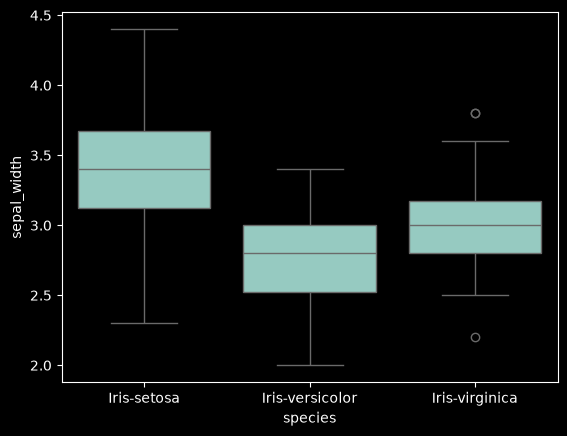

In [3]:
sns.boxplot(iris, x="species", y="sepal_width")
plt.show()

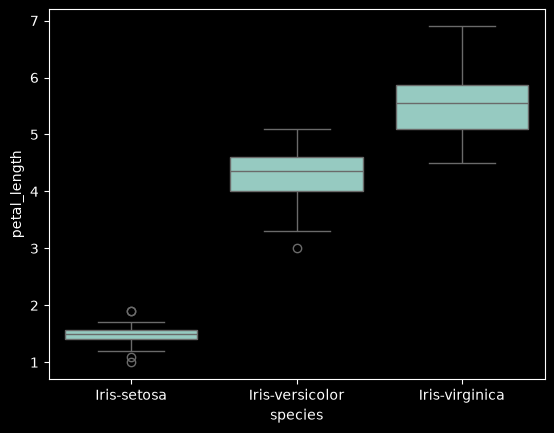

In [4]:
sns.boxplot(iris, x="species", y="petal_length")
plt.show()

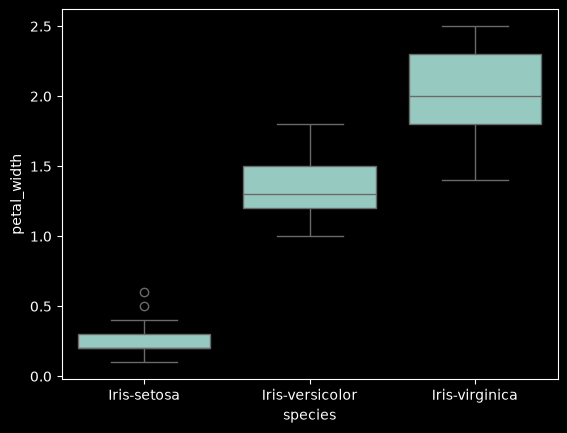

In [5]:
sns.boxplot(iris, x="species", y="petal_width")
plt.show()

From the box plots, we see that for sepal length, petal length, and petal width,
*Iris Setosa* specimens tend to have the smallest values, then *Iris Versicolor*,
and finally *Iris Virginica* specimens have the largest.

When it comes to sepal *width*, however, this trend is broken. *Iris Setosa* specimens tend
to have the *widest* sepals of the three species, despite being smallest in the other categories.
*Iris Versicolor* have the smallest sepal widths, with *Iris Virginica* being in between.

---

2\. Let's create a pairs plot comparing relationships between attributes by species.

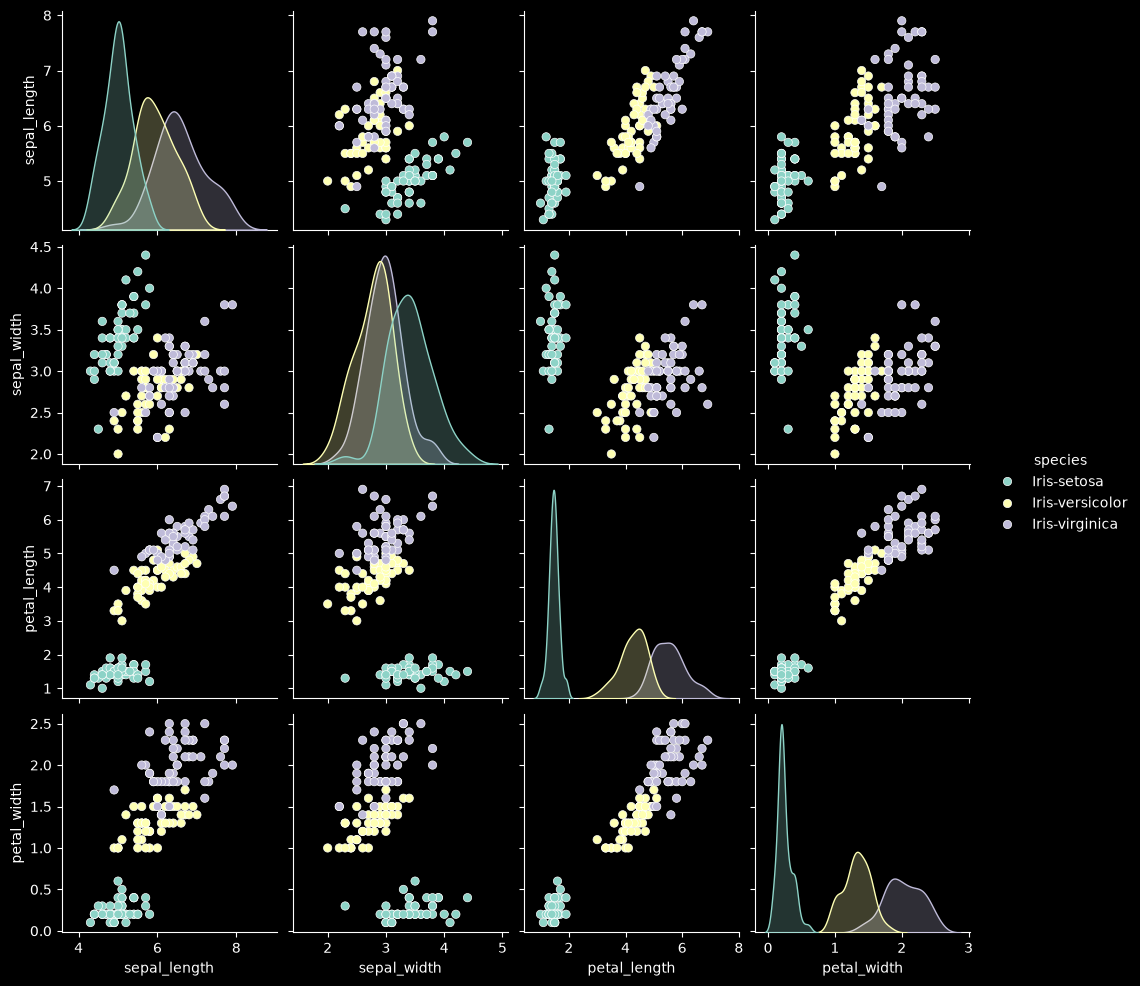

In [6]:
sns.pairplot(iris, hue="species")
plt.show()

This figure shows a scatter plot of every possible combination of two attributes,
coloured by species. This allows us to easily see possible correlations between
attributes for specific species, and see cluster separations between species
for specific pairs of attributes.

In most of the above plots, the green points (*Iris setosa*) are quite clearly visibly
separate from the other two colours, allowing *Iris setosa* specimens to be easily identified
by their attributes. Just visually, I'd say using the petal length vs petal width scatter
makes it easiest to determine whether a specimen is *Iris setosa* or not.

In that plot, there is also a rough divide between *Iris versicolor* and *Iris virginica*,
but there is some overlap nonetheless. This makes it difficult to confidently distinguish
between the two species using clustering, as there is no clear separation between them.

Let's also use the `.corr()` method to see correlations between different attributes by species.

In [7]:
iris.groupby("species").corr()

sepal_length  sepal_width  petal_length  \
species                                                                 
Iris-setosa     sepal_length      1.000000     0.746780      0.263874   
                sepal_width       0.746780     1.000000      0.176695   
                petal_length      0.263874     0.176695      1.000000   
                petal_width       0.279092     0.279973      0.306308   
Iris-versicolor sepal_length      1.000000     0.525911      0.754049   
                sepal_width       0.525911     1.000000      0.560522   
                petal_length      0.754049     0.560522      1.000000   
                petal_width       0.546461     0.663999      0.786668   
Iris-virginica  sepal_length      1.000000     0.457228      0.864225   
                sepal_width       0.457228     1.000000      0.401045   
                petal_length      0.864225     0.401045      1.000000   
                petal_width       0.281108     0.537728      0.322108   

                              petal_width  
species                                    
Iris-setosa     sepal_length     0.279092  
                sepal_width      0.279973  
                petal_length     0.306308  
                petal_width      1.000000  
Iris-versicolor sepal_length     0.546461  
                sepal_width      0.663999  
                petal_length     0.786668  
                petal_width      1.000000  
Iris-virginica  sepal_length     0.281108  
                sepal_width      0.537728  
                petal_length     0.322108  
                petal_width      1.000000

The strongest correlation here is sepal length vs petal length for *Iris virginica*
($r \approx 0.864$).

Let's plot this along with a line of best fit.

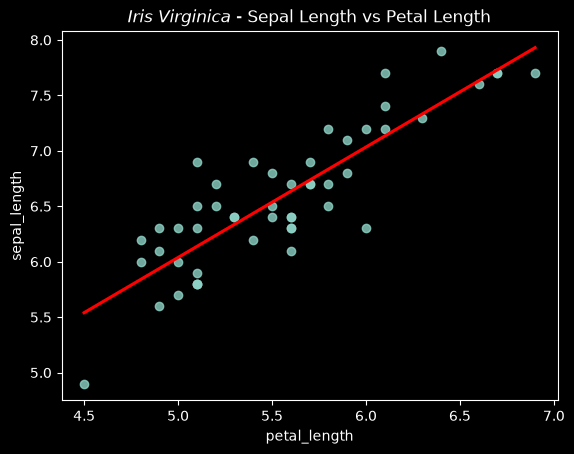

In [8]:
sns.regplot(data=iris[iris["species"] == "Iris-virginica"], x="petal_length", y="sepal_length", ci=None, line_kws={"color": "red"})
plt.title(r"$\mathit{Iris\ virginica}$ - Sepal Length vs Petal Length")
plt.show()

Which shows the strong positive correlation between sepal and petal length for this species nicely.

---

#### A2: Birdwatching

For this subsection we will be analysing birdwatching data from the Royal National Park
using a dataset from Artportalen.

1\. Let's load it and look at its structure.

In [9]:
birds = pd.read_csv("data/artportalen.csv")
birds.head(5)

,Id,Taxonsorteringsordning,Rödlistade,Artnamn,Vetenskapligt namn,Auktor,Antal,Ålder/stadium,Kön,Aktivitet,...,Provins,Församling,Startdatum,Starttid,Slutdatum,Sluttid,Kommentar,Biotop,Rapportör,Observatörer
0,97785066,55235,NaN,Koltrast,Turdus merula,"Linnaeus, 1758",2,NaN,NaN,NaN,...,Uppland,Solna,2022-01-01,NaN,2022-01-01,NaN,NaN,NaN,Björn Lindkvist,Björn Lindkvist
1,97785067,54989,NaN,Blåmes,Cyanistes caeruleus,"(Linnaeus, 1758)",2,NaN,NaN,NaN,...,Uppland,Solna,2022-01-01,NaN,2022-01-01,NaN,NaN,NaN,Björn Lindkvist,Björn Lindkvist
2,97785310,55235,NaN,Koltrast,Turdus merula,"Linnaeus, 1758",1,NaN,NaN,NaN,...,Uppland,Solna,2022-01-01,NaN,2022-01-01,NaN,NaN,NaN,Anders Eriksson,Anders Eriksson
3,97786982,54735,NaN,Sparvhök,Accipiter nisus,"(Linnaeus, 1758)",1,NaN,hona,NaN,...,Uppland,Solna,2022-01-01,NaN,2022-01-01,NaN,NaN,NaN,Anders Eriksson,Anders Eriksson
4,97786985,54944,NaN,Skata,Pica pica,"(Linnaeus, 1758)",2,NaN,NaN,NaN,...,Uppland,Solna,2021-12-30,15:57,2022-01-01,09:36,NaN,NaN,Henrik Spovin,Henrik Spovin


Abridged Data Dictionary:
* `Rödlistade`: [Conversation status](https://en.wikipedia.org/wiki/Conservation_status) of the species (`"CR"`, `"EN"`, `"VU"`, `"NT"`, `"LC"`)
if it is threatened, `NaN` otherwise.
* `Artnamn`: The name of the bird species that was observed.
* `Vetenskapligt namn`: The scientific name of the species using [binomial nomenclature](https://en.wikipedia.org/wiki/Binomial_nomenclature).
* `Auktor`: The person who first documented the species.
* `Antal`: The quantity of birds observed.
* `Ålder/stadium`: The age/life stage of the bird:
    * `"adult"`: Indicates a fully mature specimen.
    * `"pulli"`: Indicates a **nestling**, a newly hatched bird that has not left the nest.
    * `"ägg"`: An unhatched egg.
    * `"[N]K"` A bird that is in its *N*th year of life.
    For example a bird with `"2K"` means it was born in the previous calendar year.
    A plus (`+`) symbol after the `K` means the bird is *at least* in its *N*th year of life, possibly more.
    [Source](https://godisgris.se/abc-for-fagelskadare).
* `Kön`: The gender of the sighted bird:
    * `"hane"`: A male bird.
    * `"hona"`: A female bird.
    * `"i par"`: Pair(s) of male and female birds.
    * `honfärgad`: A female-coloured bird.
    * `hanfärgad`: A male-coloured bird.
* `Aktivitet`: What the sighted bird(s) are currently doing.
* `Lokalnamn`: Where the bird(s) were sighted.

---

2\. We will now look for the most **prevalent** bird species,
which I define to be the ones which have the highest number of sightings
(regardless of how many birds were observed in an individual sighting).

In [10]:
prevalence = birds.groupby("Vetenskapligt namn").size().reset_index(name="Observations").sort_values("Observations", ascending=False)
prevalence.head(10)

,Vetenskapligt namn,Observations
168,Turdus merula,718
118,Parus major,631
56,Cyanistes caeruleus,629
11,Anas platyrhynchos,531
107,Mergus merganser,522
74,Fulica atra,513
166,Troglodytes troglodytes,486
48,Columba palumbus,480
47,Columba oenas,476
72,Fringilla coelebs,452


Above we see the 10 most commonly observed bird species.

---

3\. Next, we want to visualise monthly sightings of our top 3 bird species from above.

In [11]:
birds["Startdatum"] = pd.to_datetime(birds["Startdatum"])
birds["Month"] = birds["Startdatum"].dt.month

monthly_observations = birds[birds["Vetenskapligt namn"] == "Parus major"].groupby("Month").size().reset_index(name="Observations")
monthly_observations.head(20)

,Month,Observations
0,1,144
1,2,119
2,3,129
3,4,95
4,5,111
5,6,33


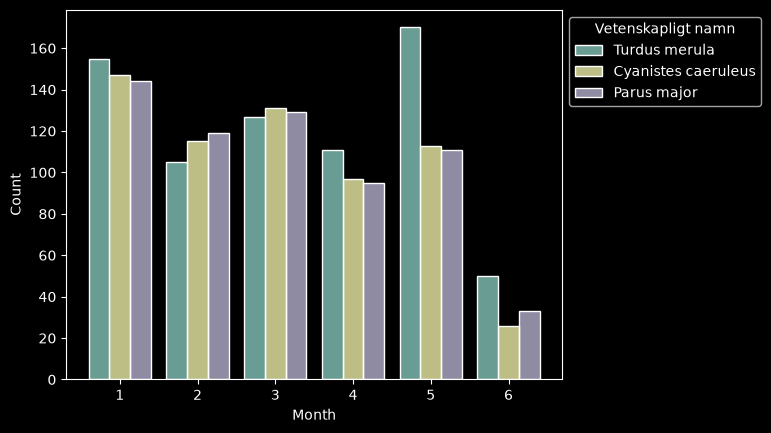

In [25]:
top_3 = prevalence["Vetenskapligt namn"][:3]
plot = sns.histplot(birds[birds["Vetenskapligt namn"].isin(top_3)], x="Month", hue="Vetenskapligt namn",
             discrete=True, shrink=0.8, multiple="dodge")
sns.move_legend(plot, "upper left", bbox_to_anchor=(1, 1))
plt.show()